In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the SMSSpamCollection file from your computer
uploaded = files.upload()

# Find the uploaded dataset filename
file_name = next(
    name for name in uploaded
    if name.startswith("SMSSpamCollection")
)

# Load the dataset
df = pd.read_csv(
    file_name,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five messages:")
display(df.head())


Saving SMSSpamCollection to SMSSpamCollection
Dataset loaded successfully!
Dataset shape: (5572, 2)

First five messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Inspect the dataset
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:

# Check the original dataset size
print("Before cleaning:", df.shape)

# Remove duplicate messages
df = df.drop_duplicates().reset_index(drop=True)

# Check the cleaned dataset
print("After cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

# Count each message category
print("\nCleaned label distribution:")
print(df["label"].value_counts())

# Calculate percentages
print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))


Before cleaning: (5572, 2)
After cleaning: (5169, 2)
Remaining duplicates: 0

Cleaned label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Label percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


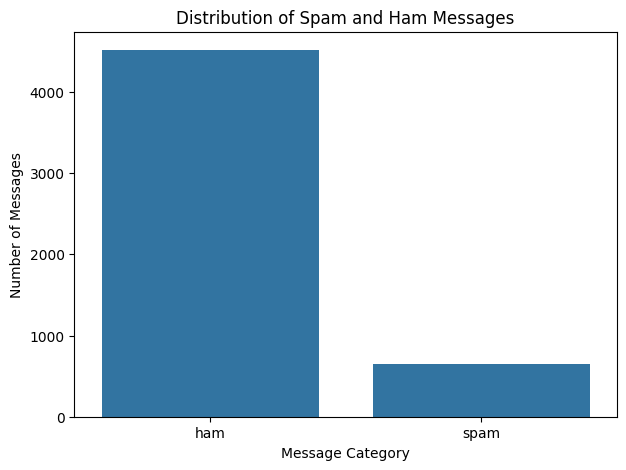

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()


In [6]:

from sklearn.model_selection import train_test_split

# Separate the messages and labels
X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())


Training messages: 4135
Testing messages: 1034

Training label distribution:
label
0    3613
1     522
Name: count, dtype: int64


In [7]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text messages into numerical features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(tfidf.vocabulary_))


Training feature matrix: (4135, 5000)
Testing feature matrix: (1034, 5000)
Number of vocabulary terms: 5000


In [8]:

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Initialize the three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate each model
results = []

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

# Display model comparison
results_df = pd.DataFrame(results)
print("\nModel Comparison:")
display(
    results_df.sort_values(
        by="F1-Score", ascending=False
    ).round(4)
)


Training Logistic Regression...
Training Multinomial Naive Bayes...
Training Random Forest...

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.9758,0.9732,0.8321,0.8971
1,Multinomial Naive Bayes,0.9720,1.0000,0.7786,0.8755
0,Logistic Regression,0.9584,0.9783,0.6870,0.8072


Random Forest Classification Report:

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.97      0.83      0.90       131

    accuracy                           0.98      1034
   macro avg       0.97      0.91      0.94      1034
weighted avg       0.98      0.98      0.98      1034



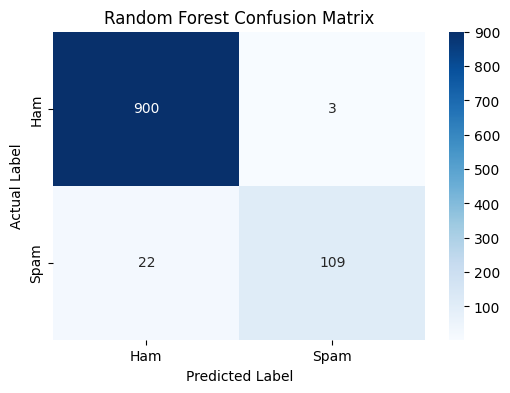

In [9]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Select the trained Random Forest model
rf_model = models["Random Forest"]

# Generate predictions specifically for Random Forest
y_pred_rf = rf_model.predict(X_test_tfidf)

# Print detailed evaluation metrics
print("Random Forest Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Ham", "Spam"],
    zero_division=0
))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [10]:

# Combine actual labels, predicted labels, and messages
error_analysis = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred_rf
})

# Find spam messages incorrectly classified as ham
missed_spam = error_analysis[
    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 0)
]

print("Spam messages missed:", len(missed_spam))
display(missed_spam.head(10))


Spam messages missed: 22


,message,actual,predicted
95,Want explicit SEX in 30 secs? Ring 02073162414...,1,0
105,You will recieve your tone within the next 24h...,1,0
168,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1,0
174,TheMob>Hit the link to get a premium Pink Pant...,1,0
230,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...,1,0
249,"Free msg. Sorry, a service you ordered from 81...",1,0
302,We currently have a message awaiting your coll...,1,0
308,Hi its LUCY Hubby at meetins all day Fri & I w...,1,0
326,Missed call alert. These numbers called but le...,1,0
329,"SMS. ac sun0819 posts HELLO:""You seem cool, wa...",1,0


In [11]:

def predict_sms(message):
    # Convert the new message using the fitted TF-IDF vectorizer
    message_tfidf = tfidf.transform([message])

    # Predict the label
    prediction = rf_model.predict(message_tfidf)[0]

    if prediction == 1:
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM (legitimate)")

# Try example messages
predict_sms("Congratulations! You have won a free prize. Call now!")
predict_sms("Hey, are we still meeting for lunch today?")


Prediction: HAM (legitimate)
Prediction: HAM (legitimate)


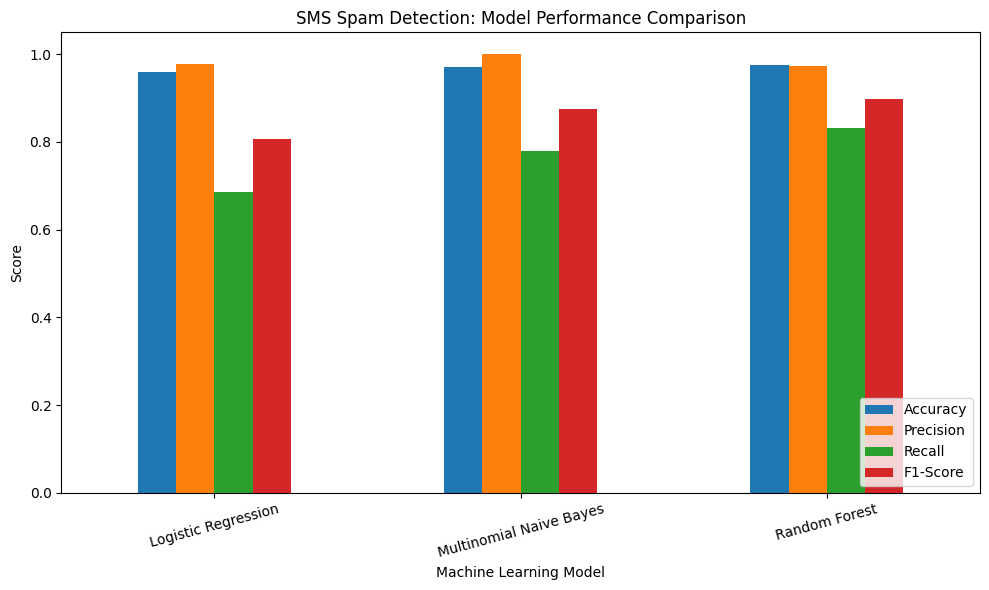

In [12]:

# Plot model comparison
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("SMS Spam Detection: Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [13]:

import joblib

# Save the model and text vectorizer together
joblib.dump(
    {
        "model": rf_model,
        "tfidf": tfidf,
        "label_mapping": {"ham": 0, "spam": 1}
    },
    "sms_spam_detector.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [14]:
from google.colab import files

files.download("sms_spam_detector.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import joblib

# Load the saved model and TF-IDF vectorizer
saved = joblib.load("sms_spam_detector.joblib")

model = saved["model"]
tfidf = saved["tfidf"]

def predict_sms(message):
    features = tfidf.transform([message])
    prediction = model.predict(features)[0]

    if prediction == 1:
        return "SPAM"
    return "HAM (Legitimate)"

# Test example messages
test_messages = [
    "Congratulations! You won a free prize. Call now!",
    "Hey, are we still meeting for lunch today?",
    "URGENT! Claim your cash reward now. Reply WIN.",
    "Hi, I will be home in 10 minutes."
]

for message in test_messages:
    print("Message:", message)
    print("Prediction:", predict_sms(message))
    print("-" * 60)


Message: Congratulations! You won a free prize. Call now!
Prediction: HAM (Legitimate)
------------------------------------------------------------
Message: Hey, are we still meeting for lunch today?
Prediction: HAM (Legitimate)
------------------------------------------------------------
Message: URGENT! Claim your cash reward now. Reply WIN.
Prediction: SPAM
------------------------------------------------------------
Message: Hi, I will be home in 10 minutes.
Prediction: HAM (Legitimate)
------------------------------------------------------------


In [17]:
from google.colab import files
uploaded = files.upload()

Saving sms_spam_detector.joblib to sms_spam_detector (1).joblib


Balanced Logistic Regression Report:

              precision    recall  f1-score   support

         Ham       0.98      0.99      0.98       903
        Spam       0.90      0.89      0.89       131

    accuracy                           0.97      1034
   macro avg       0.94      0.94      0.94      1034
weighted avg       0.97      0.97      0.97      1034



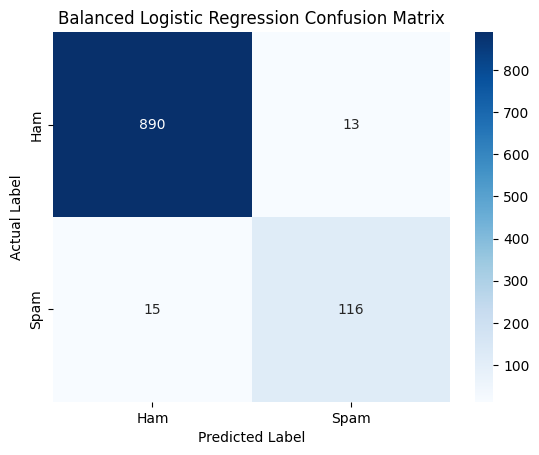

In [18]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train a Logistic Regression model with balanced class weights
balanced_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

balanced_lr.fit(X_train_tfidf, y_train)

# Predict on the same held-out test set
y_pred_balanced = balanced_lr.predict(X_test_tfidf)

print("Balanced Logistic Regression Report:\n")
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Ham", "Spam"]
))

# Display the confusion matrix
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Balanced Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


In [19]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Model comparison on the same test set:\n")

print("Random Forest")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Spam precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Spam recall:", round(recall_score(y_test, y_pred_rf), 4))
print("Spam F1-score:", round(f1_score(y_test, y_pred_rf), 4))

print("\nBalanced Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Spam precision:", round(precision_score(y_test, y_pred_balanced), 4))
print("Spam recall:", round(recall_score(y_test, y_pred_balanced), 4))
print("Spam F1-score:", round(f1_score(y_test, y_pred_balanced), 4))


Model comparison on the same test set:

Random Forest
Accuracy: 0.9758
Spam precision: 0.9732
Spam recall: 0.8321
Spam F1-score: 0.8971

Balanced Logistic Regression
Accuracy: 0.9729
Spam precision: 0.8992
Spam recall: 0.8855
Spam F1-score: 0.8923


In [20]:

import joblib

joblib.dump(
    {
        "model": rf_model,
        "tfidf": tfidf,
        "label_mapping": {"ham": 0, "spam": 1}
    },
    "sms_spam_random_forest.joblib"
)

joblib.dump(
    {
        "model": balanced_lr,
        "tfidf": tfidf,
        "label_mapping": {"ham": 0, "spam": 1}
    },
    "sms_spam_balanced_logistic.joblib"
)

print("Both models saved successfully!")


Both models saved successfully!


In [21]:

import joblib

# Save both trained models and the fitted TF-IDF vectorizer
joblib.dump(
    {"model": rf_model, "tfidf": tfidf},
    "sms_spam_random_forest.joblib"
)

joblib.dump(
    {"model": balanced_lr, "tfidf": tfidf},
    "sms_spam_balanced_logistic.joblib"
)

print("Both final models saved successfully!")


Both final models saved successfully!
